In [ ]:
from google.colab import drive
import os
import shutil

# 1. Google Drive'ı Bağla
drive.mount('/content/drive')

# 2. Drive'dan yedeklenen dosyaları yerel disk alanına kopyala
print("Yedek dosyaları Google Drive'dan indiriliyor...")
shutil.copy('/content/drive/My Drive/opencv_cuda/cv2_cuda_backup.zip', '/content/')
shutil.copy('/content/drive/My Drive/opencv_cuda/opencv_libs_backup.zip', '/content/')

# 3. Python paket klasörünü oluştur ve dosyaları çıkart
print("Python cv2 paketi kuruluyor...")
os.makedirs('/usr/local/lib/python3.13/dist-packages/cv2', exist_ok=True)
!unzip -q -o /content/cv2_cuda_backup.zip -d /usr/local/lib/python3.13/dist-packages/cv2

# 4. Paylaşılan C++ kütüphanelerini çıkart
print("Sistem paylaşımlı kütüphaneleri (.so) geri yükleniyor...")
!unzip -q -o /content/opencv_libs_backup.zip -d /usr/local/lib

# 5. Sistem dinamik kütüphane bağlayıcısını güncelle
print("Kütüphane yolları sistemde güncelleniyor...")
!ldconfig

# 6. Test Et
print("\n=== KURULUM TAMAMLANDI ===")
import cv2
cuda_devices = cv2.cuda.getCudaEnabledDeviceCount()
print(f"CUDA Destekli Cihaz Sayısı: {cuda_devices}")
if cuda_devices > 0:
    print("Tebrikler! OpenCV CUDA desteğiyle başarıyla geri yüklendi.")
    cv2.cuda.printCudaDeviceInfo(0)
else:
    print("Uyarı: Kurulum tamamlandı ancak GPU etkinleştirilmemiş olabilir. Runtime ayarlarından GPU seçtiğinize emin olun.")

Mounted at /content/drive
Yedek dosyaları Google Drive'dan indiriliyor...
Python cv2 paketi kuruluyor...
Sistem paylaşımlı kütüphaneleri (.so) geri yükleniyor...
Kütüphane yolları sistemde güncelleniyor...
/sbin/ldconfig.real: /usr/local/lib/libtbbbind_2_5.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libumf.so.1 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbb.so.12 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbbind.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_level_zero.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_level_zero_v2.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbmalloc_proxy.so.2 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libhwloc.so.15 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_opencl.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libjulia.so.1.12 is not a sym

In [ ]:
%%writefile sobel_processing.cpp


Resim başarıyla yüklendi. Boyutları: (1278, 1280, 3)


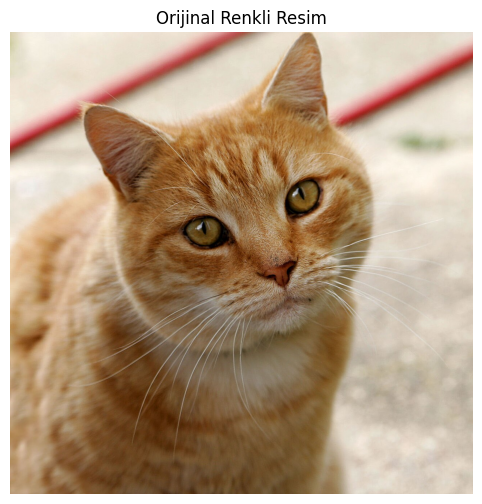

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# 1. Renkli Görüntüyü Oku (3 kanallı)
# Colab dosya sistemindeki resimm.jpg.avif dosyasını okuyoruz.
img_path = '/content/resimm.jpg.avif'
image = cv2.imread(img_path)

if image is None:
    print(f"Hata: {img_path} yolundaki resim yüklenemedi. Lütfen dosya adını veya yolunu kontrol edin.")
else:
    print(f"Resim başarıyla yüklendi. Boyutları: {image.shape}")

    # OpenCV varsayılan olarak BGR (Blue, Green, Red) formatında okur.
    # Matplotlib ile doğru göstermek için RGB'ye çeviriyoruz.
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Orijinal görüntüyü gösterelim
    plt.figure(figsize=(6, 6))
    plt.imshow(image_rgb)
    plt.title('Orijinal Renkli Resim')
    plt.axis('off')
    plt.show()

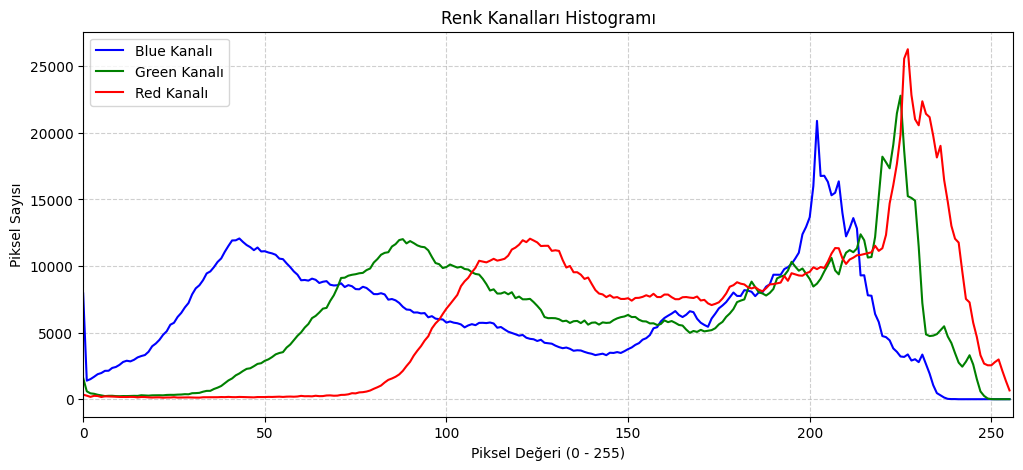

In [2]:
# 2. Her Bir Kanal İçin Histogram Çıkarılması
# Renk kanallarını ayırıyoruz: Blue, Green, Red
channels = ('b', 'g', 'r')
colors = ('blue', 'green', 'red')

plt.figure(figsize=(12, 5))
plt.title('Renk Kanalları Histogramı')
plt.xlabel('Piksel Değeri (0 - 255)')
plt.ylabel('Piksel Sayısı')

# Her kanal için histogram hesaplayıp çiziyoruz
for i, col in enumerate(channels):
    # cv2.calcHist([görüntü], [kanal_indeksi], maske, [histogram_boyutu], [değer_aralığı])
    hist = cv2.calcHist([image], [i], None, [256], [0, 256])
    plt.plot(hist, color=colors[i], label=f'{colors[i].capitalize()} Kanalı')
    plt.xlim([0, 256])

plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

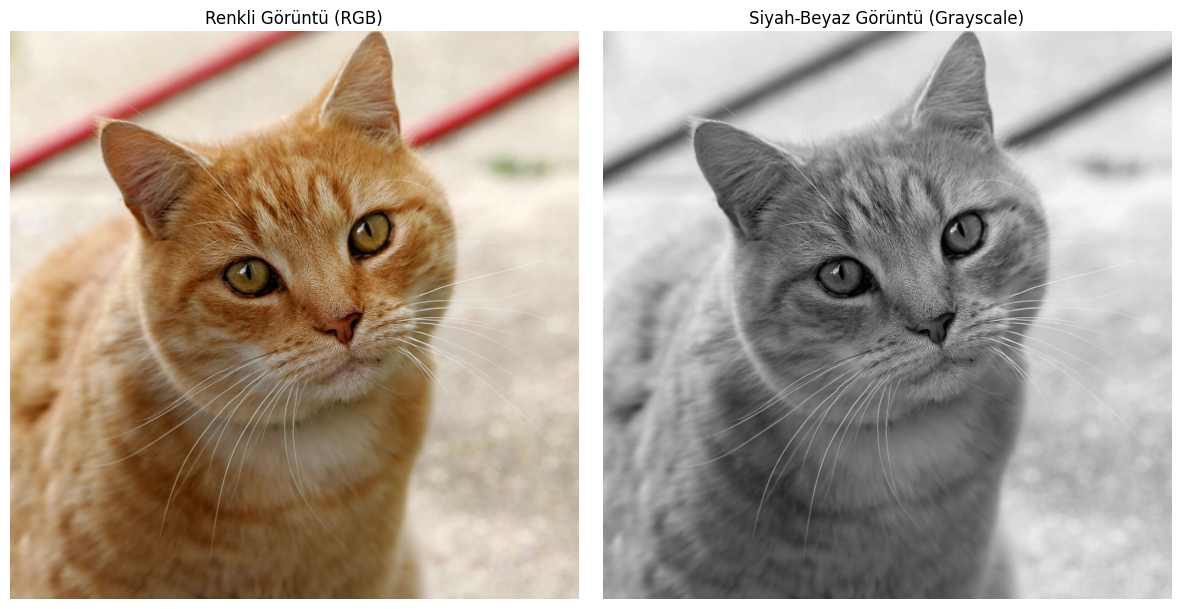

In [3]:
# 3. Siyah Beyaz (Gri Tonlamalı) Görüntüye Dönüştürme
gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Orijinal ve Siyah-Beyaz resmi yan yana gösterelim
plt.figure(figsize=(12, 6))

# Renkli Resim
plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title('Renkli Görüntü (RGB)')
plt.axis('off')

# Siyah Beyaz Resim
plt.subplot(1, 2, 2)
# Gri tonlamalı resimleri matplotlib ile gösterirken cmap='gray' parametresi eklenmelidir
plt.imshow(gray_image, cmap='gray')
plt.title('Siyah-Beyaz Görüntü (Grayscale)')
plt.axis('off')

plt.tight_layout()
plt.show()